# 02 — What does Anthropic actually earn?

**Question:** strip out the accounting noise. What are Anthropic's *real* revenue, operating income and free cash flow, and what part of the $104B GAAP loss matters for the business going forward?

**Short answer**
1. The $104B net loss in the first nine months of 2026 is *more than entirely* valuation marks ($105B; the business plus interest income netted slightly positive). $94.3B is the rising fair value of Amazon's convertible notes, and $11.0B is Google/Amazon commitments to buy shares at a price below what they're now worth. Neither is a business cost, and both stop when the notes convert at the IPO. Their economic content is **dilution**, which belongs in the share count, not in earnings (§1, `02_gaap_loss_waterfall.png`).
2. The mark implies Anthropic's own Sep-30 valuation of about **$71 per share**, ~20% above the $58.90 Series H price (§2).
3. Real revenue: $33.2B reported for 9M-2026, but the company says 5–7% came from customers breaking its usage policy who are now being cut off. Clean 9M revenue is ~$31B, and the Q3 run-rate is ~$64B rather than $68B (§3, `02_revenue_quarterly.png`).
4. Real operating income keeps stock comp and share-paid donations as costs, because owners pay for them through dilution. It was **−$1.3B (−4%)** for 9M-2026 and −3% in Q3. The company's "Adjusted Operating Margin" of 15% in Q3 adds back exactly those two costs (§4, `02_operating_margin.png`).
5. The business itself is very profitable to *serve*. Cost of revenue is 14¢ per revenue dollar, and research and training take 58¢. Profitability is a race between revenue and the training budget (§5, `02_revenue_dollar.png`).
6. Real free cash flow: $3.6B for 9M-2026 after capex. Take out interest earned on the $132B war chest and it's $1.2B. Charge stock comp and donations as owner costs and it's **−$4.1B** (§6, `02_fcf_bridge.png`).
7. Going forward, the note marks disappear. Stock comp roughly triples after the IPO (a $32B RSU backlog), donations grow by policy, and interest income lasts only as long as the cash pile (§7).

| § | Question | Chart |
|---|---|---|
| 1 | What is the $104B GAAP loss made of? | `02_gaap_loss_waterfall.png` |
| 2 | What valuation does the notes mark imply? | — |
| 3 | What is real revenue? | `02_revenue_quarterly.png` |
| 4 | What is real operating income? | `02_operating_margin.png` |
| 5 | Where does each revenue dollar go? | `02_revenue_dollar.png` |
| 6 | What is real free cash flow? | `02_fcf_bridge.png` |
| 7 | What carries forward after the IPO? | — |

**Inputs:** `data/income_statement.csv`, `quarterly_income_statement.csv`, `cash_flow.csv`, `non_gaap.csv`, `opex_by_function.csv`, `flow_detail.csv`, `convertible_notes_outstanding.csv`, `preferred_stock.csv`, `kpis.csv`.
**Output:** `data/real_earnings.csv` (metric × period), read by `03_growth_vs_compute.ipynb`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from common import *

I = wide(load('income_statement'))
Q = wide(load('quarterly_income_statement'))
CF = wide(load('cash_flow'))
FN = wide(load('opex_by_function'))
NG = load('non_gaap')
FD = load('flow_detail')
K = load('kpis').set_index('metric')
kpi = lambda m: K.loc[m, 'value'] if np.ndim(K.loc[m, 'value']) == 0 else K.loc[m, 'value'].iloc[0]

# Trailing twelve months to Sep 30 2026 = FY2025 - 9M-2025 + 9M-2026 (the filing has no quarterly cash flows).
def add_ttm(df):
    df['TTM-2026-09'] = df['FY2025'] - df['9M-2025'] + df['9M-2026']
    return df
for df in (I, CF, FN):
    add_ttm(df)

P = ['FY2023', 'FY2024', 'FY2025', '9M-2025', '9M-2026', 'TTM-2026-09']
QS = list(Q.columns)
B = 1000  # $M -> $B

## 1. What is the $104B GAAP loss made of?
**Why ask:** the headline number in every article will be "Anthropic lost $104 billion in nine months." We need to know how much of that is the business.

**Method:** walk from operating loss to net loss, line by line, for 9M-2026. The "other income (expense)" line is split using its note.

Valuation marks: $-105.3B of $-104.0B net loss = 101%


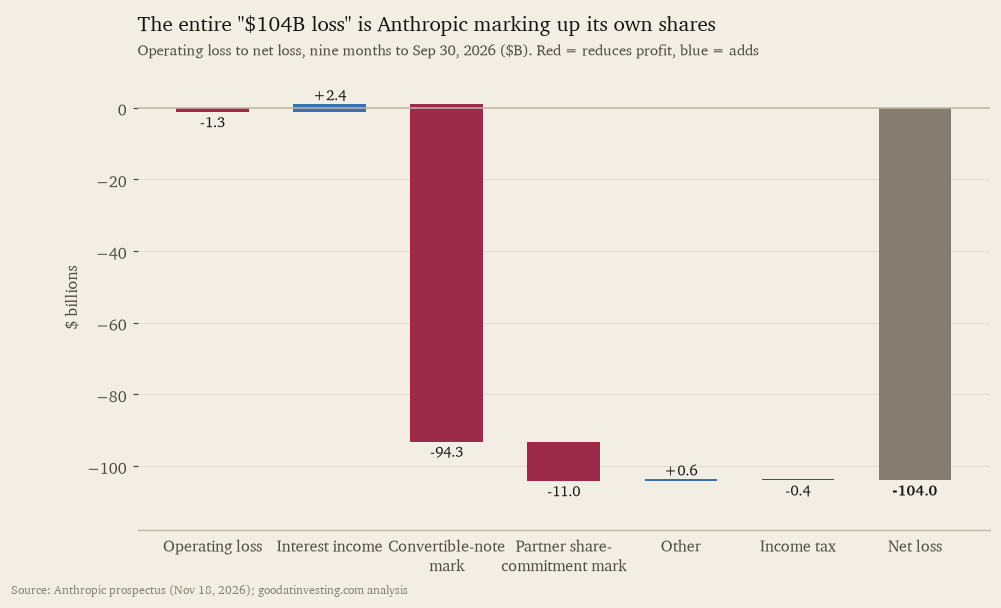

In [2]:
oie = FD[(FD.schedule == 'other_income_expense') & (FD.period == '9M-2026')].set_index('line_item').value
p = '9M-2026'
steps = [
    ('Operating loss', I.loc['Operating loss', p]),
    ('Interest income', I.loc['Interest income', p]),
    ('Convertible-note\nmark', I.loc['Change in fair value of convertible notes, derivative liabilities, and SAFEs', p]),
    ('Partner share-\ncommitment mark', oie['Recognition and change in fair value of partner financing arrangements']),
    ('Other', oie.drop(['Recognition and change in fair value of partner financing arrangements', 'Total']).sum()),
    ('Income tax', -I.loc['Provision for income taxes', p]),
]
assert abs(sum(v for _, v in steps) - I.loc['Net loss', p]) < 1
marks = steps[2][1] + steps[3][1]
print(f"Valuation marks: ${marks/B:,.1f}B of ${I.loc['Net loss', p]/B:,.1f}B net loss = {marks / I.loc['Net loss', p]:.0%}")

def waterfall(ax, steps, totals=(), fmt='{:+,.1f}'):
    """steps: (label, $B). Labels in `totals` are drawn from zero as running totals."""
    run = 0
    for x, (lab, v) in enumerate(steps):
        if lab in totals:
            bottom, height, color, run = 0, v, NEUTRAL, v
        else:
            bottom, height, color = run, v, POS if v >= 0 else NEG
            run += v
        ax.bar(x, height, bottom=bottom, color=color, width=0.62)
        top = max(bottom, bottom + height)
        bot = min(bottom, bottom + height)
        label = fmt.format(v) if lab not in totals else f'{v:,.1f}'
        ax.text(x, bot - 0.02 * ax.get_ylim()[1] if v < 0 else top, label, ha='center',
                va='top' if v < 0 else 'bottom', color=INK, fontsize=9.5, fontweight='bold' if lab in totals else 'normal')
    ax.set_xticks(range(len(steps)), [s[0] for s in steps])
    ax.axhline(0, color=AXIS, lw=1)
    ax.tick_params(axis='x', length=0, labelcolor=INK2)

fig, ax = plt.subplots(figsize=(10, 5.5))
ws = [(l, v / B) for l, v in steps] + [('Net loss', I.loc['Net loss', p] / B)]
ax.set_ylim(-118, 12)
waterfall(ax, ws, totals=('Net loss',))
ax.set_ylabel('$ billions')
ax.set_title('The entire "$104B loss" is Anthropic marking up its own shares')
subtitle(ax, 'Operating loss to net loss, nine months to Sep 30, 2026 ($B). Red = reduces profit, blue = adds')
source(fig)
save(fig, '02_gaap_loss_waterfall.png')
plt.show()

**What this shows** (`02_gaap_loss_waterfall.png`): the business lost $1.3B at the operating line and earned $2.4B of interest on its cash. Then two marks took out $105B:

| Item | 9M-2026 | What it is | Cash? | After the IPO |
|---|---|---|---|---|
| Convertible-note mark | −$94.3B | Amazon's notes convert into a fixed 1.84B shares. The S-1 carries them at fair value, so every rise in Anthropic's valuation books a "loss" equal to the noteholder's gain | No | Stops at conversion. The economic cost is the 1.84B shares, i.e. dilution |
| Partner share-commitment mark | −$11.0B | Google and Amazon agreed (Mar/Apr 2026) to buy Series G-2 at $259.14 pre-split. The valuation rose before settlement, so the below-market price is booked as a loss | No | Settled into G-2 shares ($11.8B); a small AMD put option remains |
| Interest income | +$2.4B | Treasury yield on $132B of raised cash | Yes | Lasts as long as the cash pile. It's a financing return, not an operating one |
| Other / tax | +$0.2B | Warrant gains, acquisition holdback, foreign tax | Mostly | Small |

The marks aren't fake: they record value moving from existing shareholders to Amazon and Google. But that value shows up once, as extra shares in the fully diluted count. Counting it again in earnings double-counts it. For a forward-looking view of the business, **the operating line is where the story is**.

**Next:** what valuation does the notes mark imply?

## 2. What valuation does the notes mark imply?
**Why ask:** the fair value of a fixed number of conversion shares is just a share price in disguise.

**Method:** fair value of the notes on the balance sheet ÷ Class N shares issuable on conversion. Compare with the Series H issue price, split-adjusted.

In [3]:
notes = load('convertible_notes_outstanding')
bs = wide(load('balance_sheet'))
fv = bs.loc['Convertible notes payable', '2026-09-30']
conv_shares = notes['Class N Shares Issuable on Conversion'].sum()
pref = load('preferred_stock')
h_price = pref.loc[pref.series == 'Series H-1', 'issue_price_per_common_usd'].iloc[0]
implied = fv * 1e6 / conv_shares
print(f'Notes at fair value ${fv/B:,.1f}B / {conv_shares/1e9:.2f}B conversion shares = ${implied:,.2f} per share')
print(f'Series H price (split-adjusted): ${h_price:,.2f}  -> mark is {implied/h_price-1:+.0%} above the last round')
print(f"Principal: ${notes['Principal Amount Outstanding (in millions)'].sum()/B:.1f}B -> Amazon's paper gain: ${(fv - notes['Principal Amount Outstanding (in millions)'].sum())/B:,.0f}B")
print(f"Share of accumulated deficit from note marks: ${kpi('accumulated_deficit_from_note_marks')/B:,.1f}B of ${-bs.loc['Accumulated deficit', '2026-09-30']/B:,.1f}B")

Notes at fair value $130.5B / 1.84B conversion shares = $70.91 per share
Series H price (split-adjusted): $58.90  -> mark is +20% above the last round
Principal: $6.2B -> Amazon's paper gain: $124B
Share of accumulated deficit from note marks: $135.1B of $156.2B


**What this shows:** Anthropic's auditors valued its common stock at **~$71 per share** on Sep 30, 2026, about 20% above the Series H price of $58.90. Amazon turned $6.2B of notes into ~$130B of stock. That's the best trade in this filing, and it's why $135B of the $156B accumulated deficit is a mark rather than money spent.

One more mark is coming: the notes are revalued at the IPO price when they convert. If the IPO prices above ~$71, Q4-2026 books another non-cash "loss". Ignore it for the same reason.

**Next:** with the marks set aside, how much of reported revenue is real?

## 3. What is real revenue?
**Why ask:** revenue is GAAP-clean (no gross-up games found), but the S-1 discloses two quality issues.

1. **Policy violators.** "Approximately 5% to 7%" of 9M-2026 revenue came from customers later found breaking the usage policy (think resellers and distillation). They're being cut off, with enforcement stepped up in Aug–Sep 2026. That revenue is going away.
2. **Channel partners.** Revenue sold through AWS Bedrock, Google Vertex and Azure is booked gross. The partner's cut sits in "Sales, marketing, and partnerships" and grew $4.8B year on year. Revenue is fine as reported, but ~14% of it (Q3) goes straight back out to the clouds, which are also Anthropic's suppliers and competitors.

**Method:** clean revenue = reported × (1 − 6%), with a 5–7% band, applied to the 2026 quarters only (the only period disclosed). Earlier periods probably had some too, so 2025 is slightly overstated as well.

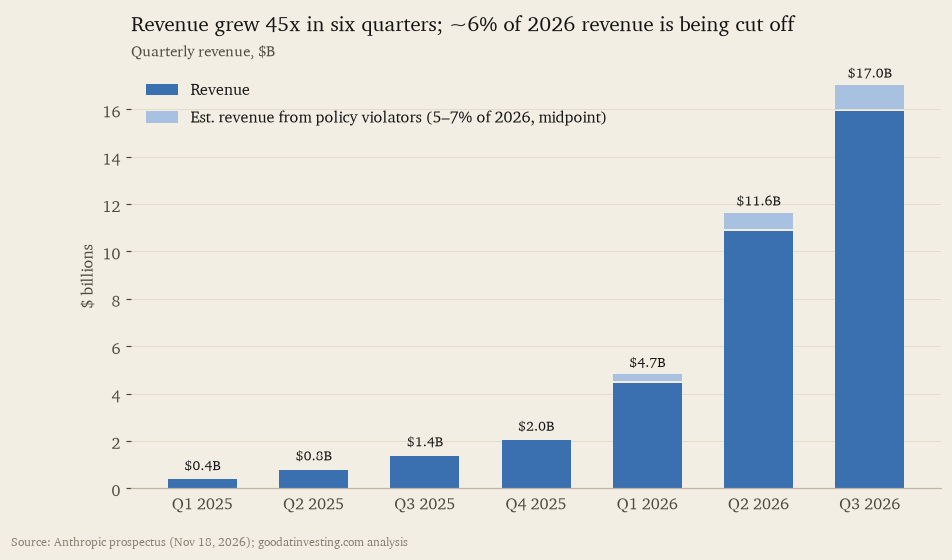

Q3-2026 run-rate: reported $67.8B, clean $63.1–64.4B
QoQ growth: {'Q2-2025': 109.0, 'Q3-2025': 76.0, 'Q4-2025': 48.0, 'Q1-2026': 132.0, 'Q2-2026': 144.0, 'Q3-2026': 47.0}


In [4]:
lo, hi = kpi('revenue_from_policy_violators_pct_low') / 100, kpi('revenue_from_policy_violators_pct_high') / 100
mid = (lo + hi) / 2
rev_q = Q.loc['Revenue']
viol_q = pd.Series([rev_q[q] * mid if q.endswith('2026') else 0 for q in QS], index=QS)

fig, ax = plt.subplots(figsize=(9.5, 5))
x = np.arange(len(QS))
ax.bar(x, (rev_q - viol_q) / B, color=SERIES[0], width=0.62, label='Revenue')
ax.bar(x, viol_q / B, bottom=(rev_q - viol_q) / B + 0.08, color=LIGHT, width=0.62,
       label='Est. revenue from policy violators (5–7% of 2026, midpoint)')
for i, q in enumerate(QS):
    ax.text(i, rev_q[q] / B + 0.25, f'${rev_q[q]/B:,.1f}B', ha='center', va='bottom', fontsize=9, color=INK)
ax.set_xticks(x, [q.replace('-', ' ') for q in QS])
ax.tick_params(axis='x', length=0, labelcolor=INK2)
ax.set_ylabel('$ billions')
ax.legend(loc='upper left')
ax.set_title('Revenue grew 45x in six quarters; ~6% of 2026 revenue is being cut off')
subtitle(ax, 'Quarterly revenue, $B')
source(fig)
save(fig, '02_revenue_quarterly.png')
plt.show()

q3 = rev_q['Q3-2026']
print(f"Q3-2026 run-rate: reported ${q3*4/B:,.1f}B, clean ${q3*4*(1-hi)/B:,.1f}–{q3*4*(1-lo)/B:,.1f}B")
print('QoQ growth:', (rev_q.pct_change() * 100).round(0).dropna().to_dict())

**What this shows** (`02_revenue_quarterly.png`): even after the haircut, the trajectory doesn't change. Q3-2026 is a ~$64B clean annual run-rate, up from $1.5B a year earlier. Growth is slowing fast in percentage terms, though: +144% in Q2, +47% in Q3. Part of the Q3 slowdown is probably the violator clean-up itself. Notebook 03 starts its projections from the clean Q3 level.

**Next:** how much operating profit does that revenue produce?

## 4. What is real operating income?
**Why ask:** the company's preferred number, Adjusted Operating Income, was +$4.1B for 9M-2026. GAAP says −$1.3B. The difference is three add-backs:

| Add-back | 9M-2026 | Our view |
|---|---|---|
| Stock-based compensation | $3.3B | **Keep as a cost.** Employees are paid in shares instead of cash, and owners pay through dilution. It's also about to triple (§7) |
| Non-cash charitable contributions (donation matching) | $2.1B | **Keep as a cost.** The company matches employee pledges with newly issued shares, and says this will *grow*. A real transfer from shareholders to charity, by policy |
| Bartz settlement (2025 only) | $1.5B | **Add back.** A one-time copyright settlement. Note the risk of copycat suits stays |

**Method:** real operating income = GAAP operating income + Bartz. We keep the company's adjusted figure alongside for reference.

In [5]:
def ng_line(measure, item):
    d = NG[(NG.measure == measure) & (NG.line_item == item)].set_index('period').value
    return d

adj = ng_line('adjusted_operating_income', 'Adjusted Operating Income (Loss)')
sbc = ng_line('adjusted_operating_income', 'Stock-based compensation expense')
don = ng_line('adjusted_operating_income', 'Non-cash charitable contributions')
for s in (adj, sbc, don):
    s['TTM-2026-09'] = s['FY2025'] - s['9M-2025'] + s['9M-2026']

gaap_oi = pd.concat([I.loc['Operating loss', P], Q.loc['Operating income (loss)', QS]])
bartz = pd.concat([I.loc['Bartz settlement', P], Q.loc['Bartz settlement', QS]])
revenue = pd.concat([I.loc['Revenue', P], rev_q])
real_oi = gaap_oi + bartz

tbl = pd.DataFrame({'Revenue': revenue, 'GAAP op. income': gaap_oi, '+ Bartz': bartz, '= Real op. income': real_oi,
                    'Real margin': real_oi / revenue, '+ SBC': sbc, '+ Donations': don, '= Company adjusted': adj,
                    'Adjusted margin': adj / revenue}).loc[P + QS]
assert (tbl['= Real op. income'] + tbl['+ SBC'] + tbl['+ Donations'] - tbl['= Company adjusted']).abs().max() <= 2
(tbl.style.format({c: '{:,.0f}' for c in tbl.columns if 'margin' not in c}).format({'Real margin': '{:.0%}', 'Adjusted margin': '{:.0%}'}))

,Revenue,GAAP op. income,+ Bartz,= Real op. income,Real margin,+ SBC,+ Donations,= Company adjusted,Adjusted margin
period,,,,,,,,,
FY2023,41.000000,-551.000000,0.000000,-551.000000,-1344%,29.000000,0.000000,-522.000000,-1273%
FY2024,386.000000,-2980.000000,0.000000,-2980.000000,-772%,192.000000,0.000000,-2788.000000,-722%
FY2025,4585.000000,-8060.000000,1500.000000,-6560.000000,-143%,1165.000000,541.000000,-4854.000000,-106%
9M-2025,2545.000000,-5224.000000,1500.000000,-3724.000000,-146%,591.000000,0.000000,-3133.000000,-123%
9M-2026,33242.000000,-1260.000000,0.000000,-1260.000000,-4%,3255.000000,2086.000000,4081.000000,12%
TTM-2026-09,35282.000000,-4096.000000,0.000000,-4096.000000,-12%,3829.000000,2627.000000,2360.000000,7%
Q1-2025,376.000000,-935.000000,0.000000,-935.000000,-249%,105.000000,0.000000,-830.000000,-221%
Q2-2025,787.000000,-1200.000000,0.000000,-1200.000000,-152%,181.000000,0.000000,-1019.000000,-129%
Q3-2025,1382.000000,-3089.000000,1500.000000,-1589.000000,-115%,305.000000,0.000000,-1284.000000,-93%


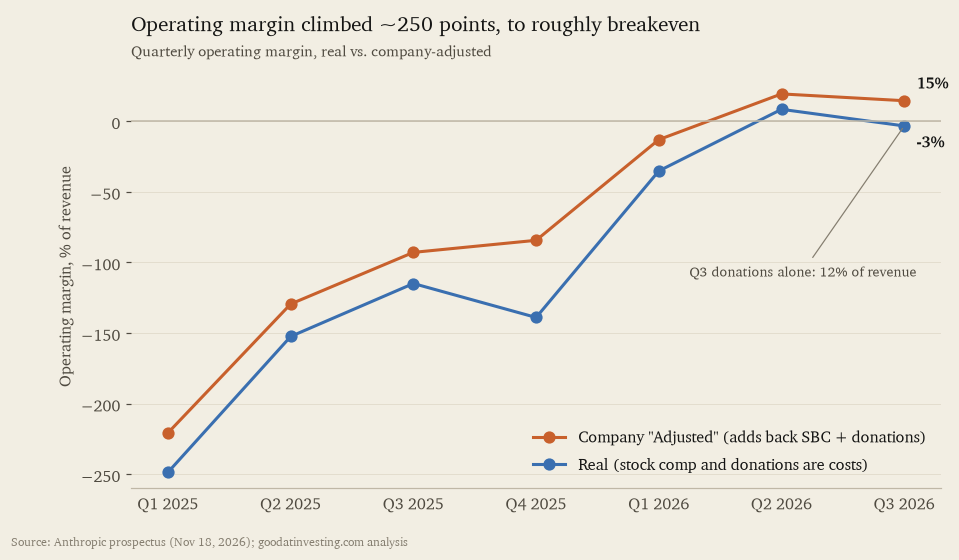

Real margin ex-donations, Q2/Q3-2026: {'Q2-2026': 8.0, 'Q3-2026': 8.0}


In [6]:
fig, ax = plt.subplots(figsize=(9.5, 5))
x = np.arange(len(QS))
m_real, m_adj = (real_oi / revenue)[QS] * 100, (adj / revenue)[QS] * 100
m_exdon = ((real_oi + don) / revenue)[QS] * 100
ax.plot(x, m_adj, color=SERIES[1], marker='o', label='Company "Adjusted" (adds back SBC + donations)')
ax.plot(x, m_real, color=SERIES[0], marker='o', label='Real (stock comp and donations are costs)')
ax.axhline(0, color=AXIS, lw=1)
for s, c, dy in ((m_adj, SERIES[1], 8), (m_real, SERIES[0], -14)):
    ax.annotate(f'{s.iloc[-1]:.0f}%', (x[-1], s.iloc[-1]), xytext=(8, dy), textcoords='offset points', color=INK, fontweight='bold')
ax.annotate(f'Q3 donations alone: {don["Q3-2026"]/rev_q["Q3-2026"]:.0%} of revenue', (x[-1], m_real.iloc[-1]),
            xytext=(4.25, -110), textcoords='data', color=INK2, fontsize=9,
            arrowprops=dict(arrowstyle='-', color=MUTED, lw=0.8))
ax.set_xticks(x, [q.replace('-', ' ') for q in QS])
ax.tick_params(axis='x', length=0, labelcolor=INK2)
ax.set_ylim(-260, 40)
ax.set_ylabel('Operating margin, % of revenue')
ax.legend(loc='lower right')
ax.set_title('Operating margin climbed ~250 points, to roughly breakeven')
subtitle(ax, 'Quarterly operating margin, real vs. company-adjusted')
source(fig)
save(fig, '02_operating_margin.png')
plt.show()
print('Real margin ex-donations, Q2/Q3-2026:', m_exdon[['Q2-2026', 'Q3-2026']].round(0).to_dict())

**What this shows** (`02_operating_margin.png`): the improvement is real and enormous. Real operating margin went from −249% in Q1-2025 to about breakeven: +8% in Q2-2026 and −3% in Q3-2026. The company's 15% Q3 adjusted margin is ~18 points of add-backs, and two-thirds of those are share-paid donations (12% of Q3 revenue). Without the donations, Q3's real margin would be +8%. Whether to count them is the reader's call, but they're dilution all the same, and the company says they'll grow.

**Next:** why is the margin only breakeven at a $68B run-rate? Where does the money go?

## 5. Where does each revenue dollar go?
**Why ask:** the income statement groups costs by *nature* (compute, people). Note 8 regroups the same costs by *function*. Cost of revenue is mostly the compute that serves customers, and R&D is mostly the compute that trains models. That split separates "is the product profitable?" from "is the company investing heavily?".

**Method:** each functional line ÷ revenue, FY2025 vs 9M-2026 (Bartz excluded).

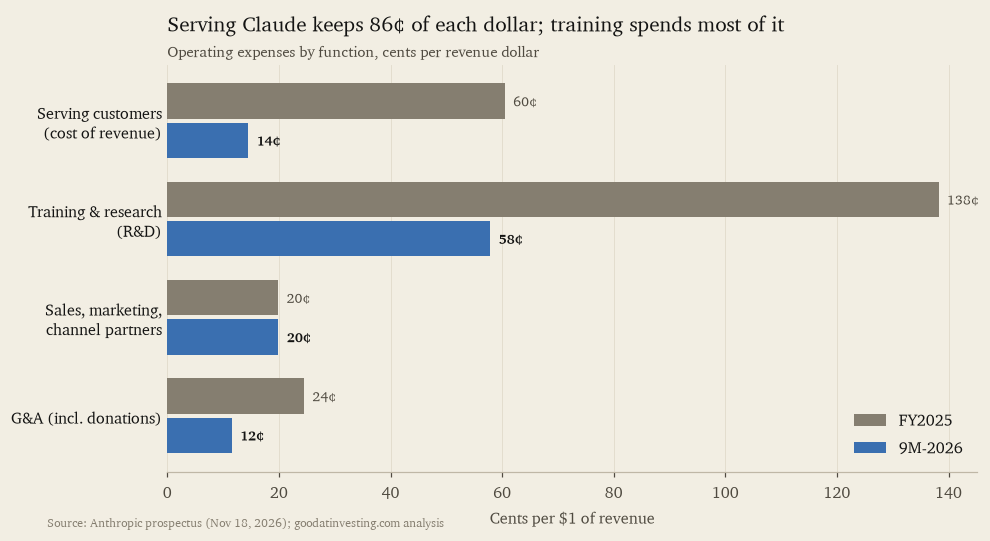

In [7]:
fn = FN.drop(['Bartz settlement', 'Total operating expenses'])[['FY2025', '9M-2026']] / I.loc['Revenue', ['FY2025', '9M-2026']] * 100
labels = {'Cost of revenue': 'Serving customers\n(cost of revenue)', 'Research and development': 'Training & research\n(R&D)',
          'Sales and marketing': 'Sales, marketing,\nchannel partners', 'General and administrative': 'G&A (incl. donations)'}
fn = fn.rename(index=labels).iloc[::-1]
fig, ax = plt.subplots(figsize=(9.5, 4.8))
y = np.arange(len(fn))
h = 0.36
ax.barh(y + h / 2 + 0.02, fn['FY2025'], height=h, color=NEUTRAL, label='FY2025')
ax.barh(y - h / 2 - 0.02, fn['9M-2026'], height=h, color=SERIES[0], label='9M-2026')
for i, (a, b) in enumerate(zip(fn['FY2025'], fn['9M-2026'])):
    ax.text(a + 1.5, i + h / 2 + 0.02, f'{a:.0f}¢', va='center', fontsize=9, color=INK2)
    ax.text(b + 1.5, i - h / 2 - 0.02, f'{b:.0f}¢', va='center', fontsize=9, color=INK, fontweight='bold')
ax.set_yticks(y, fn.index)
ax.tick_params(axis='y', length=0, labelcolor=INK)
ax.grid(axis='y', visible=False); ax.grid(axis='x', visible=True)
ax.set_xlabel('Cents per $1 of revenue')
ax.legend(loc='lower right')
gm = 100 - fn.loc[labels['Cost of revenue'], '9M-2026']
ax.set_title(f'Serving Claude keeps {gm:.0f}¢ of each dollar; training spends most of it')
subtitle(ax, 'Operating expenses by function, cents per revenue dollar')
source(fig)
save(fig, '02_revenue_dollar.png')
plt.show()

**What this shows** (`02_revenue_dollar.png`): an **~86% gross margin** in 9M-2026, software-like and up from 40% in FY2025. Inference is a great business. The whole operating loss comes from R&D: 58¢ of every dollar, mostly compute for training the next models. It's down from 138¢ in FY2025 only because revenue grew faster than the training budget.

So "when does Anthropic become profitable?" really asks whether revenue can keep outgrowing the training compute it has already signed up for. Notebook 03 takes that on.

Caveat: the compute pool is shared and the company allocates it across functions with its own methodology. The split is management's, not a physical meter.

**Next:** does the cash look like the income statement?

## 6. What is real free cash flow?
**Why ask:** cash is harder to dress up than earnings, and the S-1 warns that its cash profile is changing as it buys and leases its own data center equipment.

**Method:** a three-step ladder, 9M-2026 in the chart and all periods in the table.
- **FCF** = operating cash flow − purchases of PP&E − prepayments for leased equipment − finance-lease principal. The standard measure.
- **Operating FCF** = FCF − interest income. Interest on $132B of raised cash is a financing return, and it disappears if the cash gets spent on compute. Taxes on it are negligible today.
- **Owner FCF** = Operating FCF − stock comp − share-paid donations: what's left if those costs were paid in cash (or bought back to offset dilution).

Not deducted, but shown in the table: equipment obtained through new finance leases ($1.8B in 9M-2026). It's capex funded by the lessor. Its cost reaches cash flow later, as lease principal.

,Operating cash flow,of which working capital,Capex + equipment prepayments + lease principal,= FCF,− Interest income,= Operating FCF,− SBC − donations,= Owner FCF,Owner FCF margin,memo: finance-lease equipment
period,,,,,,,,,,
FY2023,-1627.000000,-1173.000000,-2.000000,-1629.000000,-69.000000,-1698.000000,-29.000000,-1727.000000,-4212%,0.000000
FY2024,-5692.000000,-3037.000000,-15.000000,-5707.000000,-106.000000,-5813.000000,-192.000000,-6005.000000,-1556%,0.000000
FY2025,-2637.000000,3270.000000,-185.000000,-2822.000000,-431.000000,-3253.000000,-1706.000000,-4959.000000,-108%,0.000000
9M-2025,-2024.000000,2364.000000,-162.000000,-2186.000000,-239.000000,-2425.000000,-591.000000,-3016.000000,-119%,0.000000
9M-2026,6569.000000,427.000000,-2968.000000,3601.000000,-2359.000000,1242.000000,-5341.000000,-4099.000000,-12%,1759.000000
TTM-2026-09,5956.000000,1333.000000,-2991.000000,2965.000000,-2551.000000,414.000000,-6456.000000,-6042.000000,-17%,1759.000000


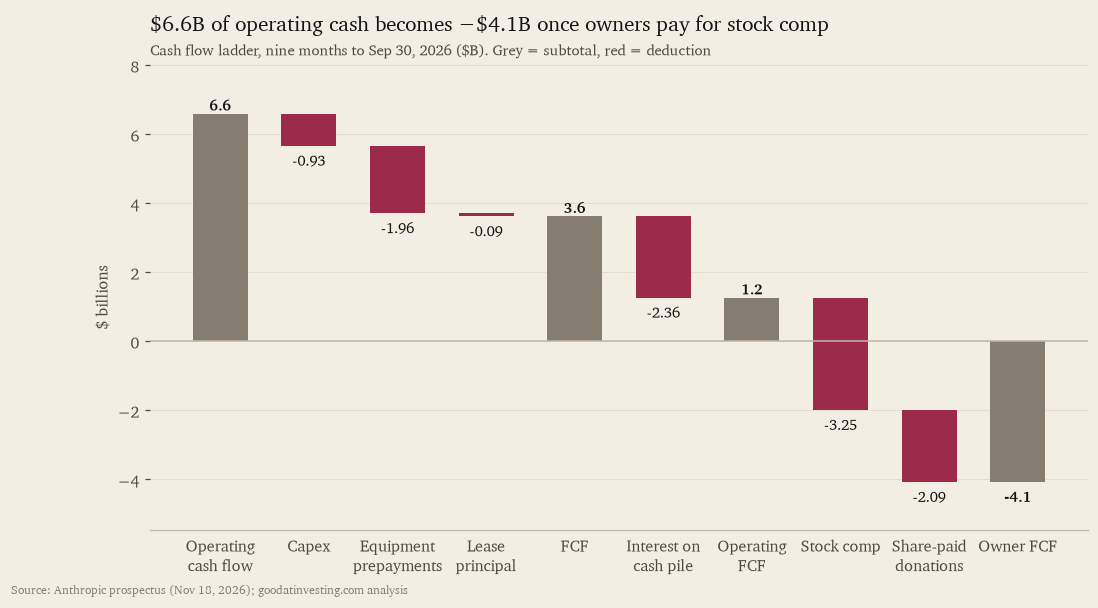

In [8]:
sup = FD[FD.schedule == 'supplemental_cash_flow']
fl_rou = wide(sup).loc['Right-of-use assets obtained in exchange for finance lease liabilities']
fl_rou['TTM-2026-09'] = fl_rou['FY2025'] - fl_rou['9M-2025'] + fl_rou['9M-2026']

cfo = CF.loc['Net cash provided by (used in) operating activities', P]
ppe = CF.loc['Purchases of property and equipment', P]
prepay = CF.loc['Prepayments for leased assets and equipment', P]
flp = CF.loc['Principal payments for finance leases', P]
fcf = cfo + ppe + prepay + flp
interest = I.loc['Interest income', P]
op_fcf = fcf - interest
owner_fcf = op_fcf - sbc[P] - don[P]
wc = CF.loc[['Accounts receivable, net', 'Prepaid expenses and other assets', 'Accounts payable, accrued expenses, and other liabilities',
             'Lease liabilities', 'Deferred revenue'], P].sum()

ftbl = pd.DataFrame({'Operating cash flow': cfo, 'of which working capital': wc, 'Capex + equipment prepayments + lease principal': ppe + prepay + flp,
                     '= FCF': fcf, '− Interest income': -interest, '= Operating FCF': op_fcf, '− SBC − donations': -(sbc[P] + don[P]),
                     '= Owner FCF': owner_fcf, 'Owner FCF margin': owner_fcf / I.loc['Revenue', P],
                     'memo: finance-lease equipment': fl_rou[P]})
display(ftbl.style.format('{:,.0f}').format({'Owner FCF margin': '{:.0%}'}))

p = '9M-2026'
fsteps = [('Operating\ncash flow', cfo[p]), ('Capex', ppe[p]), ('Equipment\nprepayments', prepay[p]), ('Lease\nprincipal', flp[p]),
          ('FCF', fcf[p]), ('Interest on\ncash pile', -interest[p]), ('Operating\nFCF', op_fcf[p]),
          ('Stock comp', -sbc[p]), ('Share-paid\ndonations', -don[p]), ('Owner FCF', owner_fcf[p])]
fig, ax = plt.subplots(figsize=(11, 5.5))
ax.set_ylim(-5.5, 8)
waterfall(ax, [(l, v / B) for l, v in fsteps], totals=('Operating\ncash flow', 'FCF', 'Operating\nFCF', 'Owner FCF'), fmt='{:+,.2f}')
ax.set_ylabel('$ billions')
ax.set_title('$6.6B of operating cash becomes −$4.1B once owners pay for stock comp')
subtitle(ax, 'Cash flow ladder, nine months to Sep 30, 2026 ($B). Grey = subtotal, red = deduction')
source(fig)
save(fig, '02_fcf_bridge.png')
plt.show()

**What this shows** (`02_fcf_bridge.png`): Anthropic produced its first positive operating cash flow ($6.6B in 9M-2026). Working capital didn't flatter it: receivables ate $7.1B, payables and deferred revenue gave about the same back. But most of what's left after capex is interest on the cash raised. The business itself made ~$1.2B, and once stock comp and donations are charged as owner costs, it's −$4.1B (−12% of revenue).

That's still a huge improvement: owner FCF was −$5.0B on $4.6B of revenue in FY2025.

**Next:** which of these items persist after the IPO?

## 7. What carries forward after the IPO?
**Why ask:** the post's numbers should describe the company investors are buying, not the private one.

In [9]:
q3 = 'Q3-2026'
rsu, catchup, opt = kpi('rsu_unrecognized_sbc'), kpi('rsu_sbc_catchup_at_ipo'), kpi('option_unrecognized_sbc')
# ponytail: straight-line the post-catch-up RSU backlog over 3 years; accelerated attribution front-loads it, so year 1 is understated
sbc_fwd_q = (rsu - catchup) / 12 + opt / 4.8  # backlog only; new grants come on top
print(f'Q3-2026 SBC: ${sbc[q3]/B:.2f}B/quarter ({sbc[q3]/rev_q[q3]:.1%} of revenue)')
print(f'At IPO: one-time catch-up of ~${catchup/B:.1f}B, then the ${(rsu-catchup)/B:.1f}B RSU backlog + ${opt/B:.1f}B options')
print(f'  -> ~${sbc_fwd_q/B:.1f}B/quarter from the backlog alone, before new grants = {sbc_fwd_q/rev_q[q3]:.0%} of Q3 revenue')

Q3-2026 SBC: $1.07B/quarter (6.3% of revenue)
At IPO: one-time catch-up of ~$8.2B, then the $24.1B RSU backlog + $1.8B options
  -> ~$2.4B/quarter from the backlog alone, before new grants = 14% of Q3 revenue


| Item | Q3-2026 | After the IPO |
|---|---|---|
| Convertible-note / partner marks | −$23.5B (non-operating) | **Gone**, after one final mark at the IPO price. Their cost lives on as ~1.84B extra shares |
| Interest income | +$1.2B | **Shrinks** as cash goes into compute. IPO proceeds top it up for a while |
| Stock comp | $1.1B (6% of revenue) | **Jumps.** An ~$8.2B one-time charge in the IPO quarter, then ~$2.4B+/quarter from the RSU backlog alone before new grants. Roughly double to triple today's charge |
| Share-paid donations | $2.0B (12% of revenue) | **Grows** by stated policy. Lumpy |
| Policy-violator revenue | ~6% of revenue | **Being removed** |
| Bartz-type settlements | — | One-offs, but copyright litigation is a live risk |

So the forward-looking "real" picture at the Q3 run-rate: **~$64B of clean revenue at about breakeven real operating margin**. Within that, an ~86% gross margin pays for a training budget of more than half of revenue, plus heavier stock comp to come.

## Findings, by section
1. Valuation marks on notes and partner share commitments ($105B) exceed the whole 9M-2026 GAAP loss ($104B) on notes and partner share commitments. They aren't a business cost; their substance is dilution.
2. The notes mark implies ~$71/share at Sep 30, 2026, ~20% above Series H ($58.90 split-adjusted).
3. Clean revenue is ~6% below reported for 2026, a ~$64B Q3 run-rate. QoQ growth slowed from 144% to 47%.
4. Real operating margin went from −249% (Q1-25) to −3% (Q3-26). The company's 15% adjusted margin adds back SBC and share-paid donations.
5. Gross margin is ~86%. R&D (mostly training compute) is 58% of revenue and is the whole story of profitability.
6. 9M-2026: FCF $3.6B, operating FCF (ex-interest) $1.2B, owner FCF −$4.1B.
7. After the IPO, the marks disappear but stock comp roughly doubles to triples.

**Caveats:** no quarterly cash flow statement, so cash metrics are 9M/TTM only. The 5–7% violator share is disclosed for 9M-2026 only. The functional cost split is management's allocation of a shared compute pool. Interest income is treated as fully cash.

**Open items:** re-run when the priced S-1 gives the IPO-quarter SBC charge and proceeds.

In [10]:
# Hand-off for 03 and research.ipynb
out = pd.concat([
    revenue.rename('revenue'), (revenue * (1 - mid)).where(revenue.index.str.contains('2026') & ~revenue.index.str.startswith('TTM')).rename('clean_revenue'),
    gaap_oi.rename('gaap_operating_income'), adj.reindex(P + QS).rename('adjusted_operating_income'),
    real_oi.rename('real_operating_income'), sbc.reindex(P + QS).rename('sbc'), don.reindex(P + QS).rename('donations'),
    cfo.rename('operating_cash_flow'), fcf.rename('fcf'), interest.rename('interest_income'),
    op_fcf.rename('operating_fcf'), owner_fcf.rename('owner_fcf'),
], axis=1).loc[P + QS]
out.index.name = 'period'
real = out.reset_index().melt(id_vars='period', var_name='metric').dropna().assign(unit='millions_usd')
real[['metric', 'period', 'value', 'unit']].to_csv(DATA / 'real_earnings.csv', index=False)
print(len(real), 'rows -> data/real_earnings.csv')

112 rows -> data/real_earnings.csv
